In [37]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import statsmodels.api as sm
import xgboost as xgb
from scipy import stats
from sklearn.model_selection import train_test_split, KFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
warnings.filterwarnings('ignore')

plt.rcParams.update({'axes.titlesize': 16, 'axes.titleweight': 'bold',
                     'axes.titlelocation': 'left', 'axes.titlepad': 40})

path = "misc_c_surveillance.csv"
data = pd.read_csv(path)
data.head(5)

,Case ID,Census Region,Sex,Age Group,Ethnicity,White Race,Black Race,Other Race,Unknown Race,MIS-C Onset (Month/Year),...,Treated with Immune modulators,Treated with Antiplatelets,Treated with Anticoagulation,Dialysis,First IVIG,Second IVIG,Vaccine Eligiblity,Vaccination Status,Number of Doses Received,Vaccine Type
0,1,South,Male,12-15 years,Unknown,False,True,False,False,01/2021,...,False,True,False,False,True,False,Vaccine ineligible,NaN,NaN,NaN
1,3619,Northeast,Male,1-4 years,Unknown,False,False,False,True,11/2021,...,False,True,True,False,True,False,Vaccine ineligible,NaN,NaN,NaN
2,2,West,Male,5-11 years,Hispanic or Latino,False,False,True,False,10/2020,...,False,True,True,False,True,False,Vaccine ineligible,NaN,NaN,NaN
3,3,South,Male,1-4 years,Not Hispanic or Latino,True,False,False,False,09/2020,...,True,True,True,False,False,False,Vaccine ineligible,NaN,NaN,NaN
4,4,South,Female,12-15 years,Unknown,False,False,False,True,10/2021,...,False,True,True,False,True,False,Vaccine eligible,Unknown,NaN,NaN


The dataset has **9,332 rows** and **56 columns**.

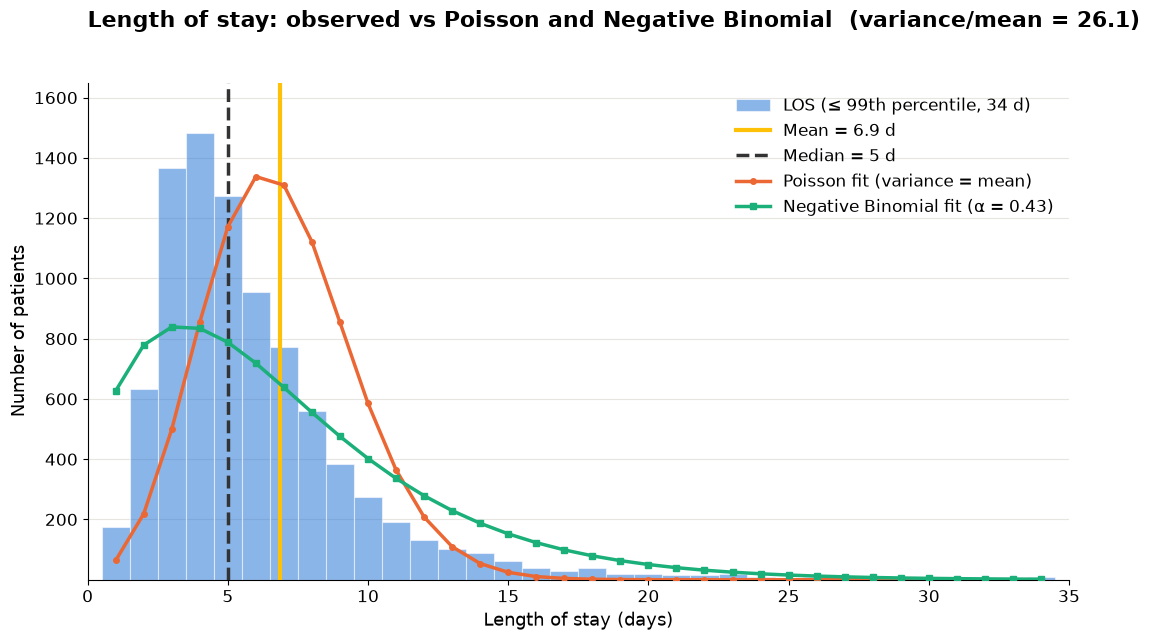

In [38]:
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
plt.style.use('default')

los = data['Hospital Length of Stay (Days)']
los = los[los >= 1]

mean_los   = los.mean()
median_los = los.median()
p99_los    = np.percentile(los, 99)
los_trun   = los[los <= p99_los]

fig, ax = plt.subplots(figsize=(11, 6.5), facecolor='white')
ax.set_facecolor('white')

# Histogram: one bar per day, semi-transparent
ax.hist(los_trun, bins=np.arange(0.5, p99_los + 1.5, 1),
        color='#2a78d6', alpha=0.55, edgecolor='white', linewidth=0.8,
        label=f'LOS (≤ 99th percentile, {p99_los:.0f} d)')

# Mean: solid yellow; Median: dashed dark grey
ax.axvline(mean_los, color='#ffc107', linewidth=3, linestyle='-', zorder=5,
           label=f'Mean = {mean_los:.1f} d')
ax.axvline(median_los, color='#333333', linewidth=2.5, linestyle='--', zorder=5,
           label=f'Median = {median_los:.0f} d')

# Expected counts under Poisson and Negative Binomial (same mean)
k = np.arange(1, int(p99_los) + 1)
pois_counts = stats.poisson.pmf(k, mean_los) * len(los)
nb_fit = sm.NegativeBinomial(los.values, np.ones(len(los))).fit(disp=0)
alpha  = nb_fit.params[-1]
size   = 1 / alpha
nb_counts = stats.nbinom.pmf(k, size, size / (size + mean_los)) * len(los)

ax.plot(k, pois_counts, color='#eb6834', lw=2.5, marker='o', ms=4, zorder=6,
        label='Poisson fit (variance = mean)')
ax.plot(k, nb_counts, color='#1baf7a', lw=2.5, marker='s', ms=4, zorder=6,
        label=f'Negative Binomial fit (α = {alpha:.2f})')

# Axes: x from 0; y ticks every 200 up to 1600, a little space above
ax.set_xlim(0, p99_los + 1)
ax.set_ylim(0, 1650)
ax.set_yticks(range(200, 1601, 200))

ax.set_xlabel('Length of stay (days)', fontsize=13)
ax.set_ylabel('Number of patients', fontsize=13)
ax.set_title(f'Length of stay: observed vs Poisson and Negative Binomial  '
             f'(variance/mean = {los.var()/mean_los:.1f})',
             loc='left', fontsize=16, fontweight='bold', pad=40)
ax.tick_params(labelsize=12)
ax.grid(axis='y', color='#e6e5e0')
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(fontsize=12, frameon=False)

plt.tight_layout()
plt.savefig('los_histogram.png', dpi=150, bbox_inches='tight')
plt.show()

**Why Negative Binomial?**

- The variance is **26 times** the mean (a Poisson model assumes they are equal).
- The **Poisson** curve (orange) is too narrow: it peaks too late and predicts almost no stays over 15 days.
- The **Negative Binomial** curve (green) captures the long right tail much better, so NB is used for modelling LOS.
- The mean (6.9 d) is above the median (5 d) because of a small number of very long stays.

In [39]:
los = data['Hospital Length of Stay (Days)'].dropna()
mean_los = los.mean()
var_los  = los.var()

* ratio ≈ 1       → Poisson is fine
* ratio > 1       → Negative Binomial needed
* ratio >> 1      → Strong overdispersion

In [40]:
disp_ratio = var_los / mean_los
print("=" * 40)
print(f"  Mean:              {mean_los:.3f}")
print(f"  Variance:          {var_los:.3f}")
print(f"  Variance/Mean:     {disp_ratio:.3f}")
print(f"  Overdispersed:     {disp_ratio > 1}")
print("=" * 40)

  Mean:              6.822
  Variance:          178.168
  Variance/Mean:     26.118
  Overdispersed:     True


Census Region: count suppressed values

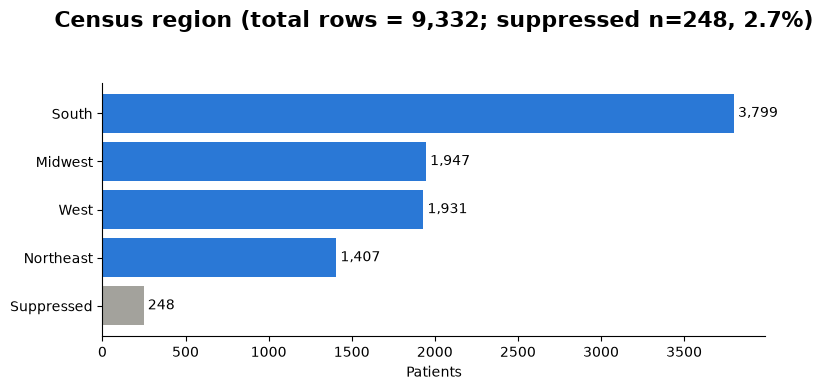

In [41]:
import matplotlib.pyplot as plt
plt.style.use('default')

reg    = data['Census Region'].replace('data suppressed', 'Suppressed')
counts = reg.value_counts()
n_supp = counts['Suppressed']
pct    = n_supp / len(data) * 100

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(counts.index[::-1], counts.values[::-1],
               color=['#a3a29c' if r == 'Suppressed' else '#2a78d6' for r in counts.index[::-1]])
ax.bar_label(bars, fmt='{:,.0f}', padding=3)
ax.set_title(f'Census region (total rows = {len(data):,}; suppressed n={n_supp}, {pct:.1f}%)',
             fontsize=16, fontweight='bold', pad=40)
ax.set_xlabel('Patients')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()


The dataset has **9,332 rows**. Census region was suppressed for **248 patients (2.7%)**.

Zero LOS: same-day discharges (severity and age)

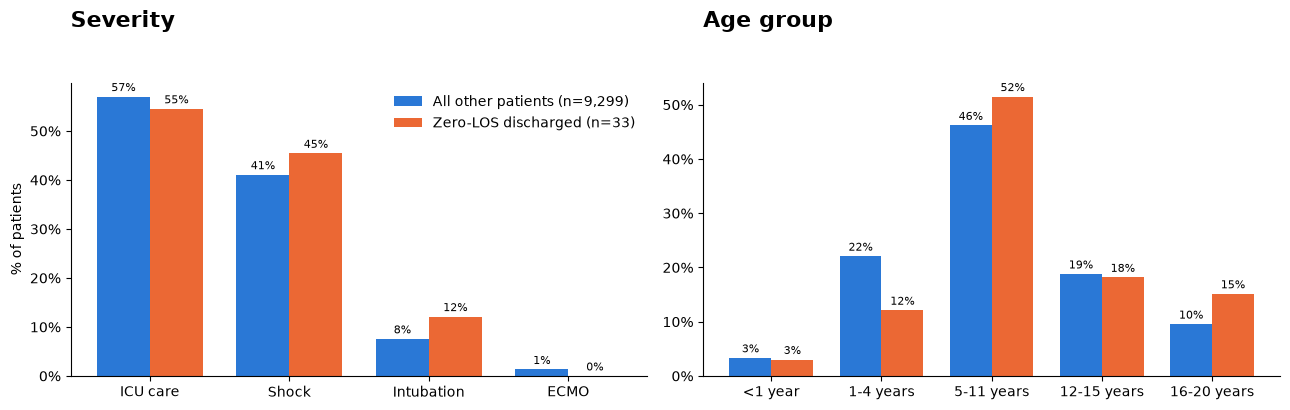

In [42]:
# Zero LOS: severity and age of same-day discharges vs all other patients
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

plt.style.use('default')

los = data['Hospital Length of Stay (Days)']
zero = (data['Outcome'] == 'Discharged') & (los == 0)
grp = np.where(zero, 'Zero-LOS discharged', 'All other patients')
sev = ['ICU Level of Care', 'Shock', 'Intubation or Mechanical Ventilation', 'ECMO']
pct = (data[sev].astype(float).groupby(grp).mean() * 100).T
age = pd.crosstab(data['Age Group'], grp, normalize='columns') * 100
age = age.reindex(['<1 year', '1-4 years', '5-11 years', '12-15 years', '16-20 years'])

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for a, tbl, labels, title in [
    (ax[0], pct, ['ICU care', 'Shock', 'Intubation', 'ECMO'], 'Severity'),
    (ax[1], age, age.index, 'Age group')]:
    x, w = np.arange(len(tbl)), 0.38
    b1 = a.bar(x - w / 2, tbl['All other patients'], w, color='#2a78d6',
               label=f"All other patients (n={(~zero).sum():,})")
    b2 = a.bar(x + w / 2, tbl['Zero-LOS discharged'], w, color='#eb6834',
               label=f"Zero-LOS discharged (n={zero.sum()})")
    a.bar_label(b1, fmt='%.0f%%', padding=2, fontsize=8)
    a.bar_label(b2, fmt='%.0f%%', padding=2, fontsize=8)
    a.set_xticks(x, labels)
    a.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    a.set_title(title, loc='left', fontsize=16, fontweight='bold', pad=40)
    a.spines[['top', 'right']].set_visible(False)
ax[0].set_ylabel('% of patients')
ax[0].legend(frameon=False)
plt.tight_layout()
plt.show()

#### Zero LOS: severe cases discharged the same day

- Negative LOS: 0
- Zero LOS: 39
- Zero LOS & discharged: 33, of which **19** had ICU care or shock
- Same-day discharges are about as severe as other patients: ICU care **55% vs 57%**, shock **45% vs 41%**.
- A complete stay of 0 days is clinically implausible for these severe cases. They are **most likely same-day transfers** to another hospital, not data-entry errors.
- **Handling:** the 19 severe same-day discharges are excluded in cleaning (Step 6), and a sensitivity analysis checks whether keeping them changes the results.

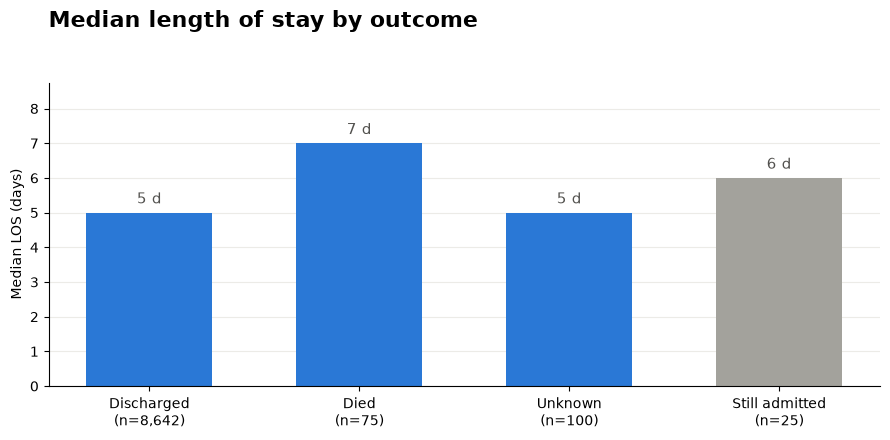

In [43]:
# 4 — Median LOS by outcome
import matplotlib.pyplot as plt
plt.style.use('default')

BLUE, GREY, INK = '#2a78d6', '#a3a29c', '#52514e'

los_all = pd.to_numeric(data['Hospital Length of Stay (Days)'], errors='coerce')
outc    = data['Outcome']
order   = ['Discharged', 'Died', 'Unknown', 'Still admitted']

vals = [los_all[outc == o].dropna() for o in order]
med  = [v.median() for v in vals]

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar([f"{o}\n(n={len(v):,})" for o, v in zip(order, vals)], med, width=0.6,
              color=[GREY if o == 'Still admitted' else BLUE for o in order])
ax.bar_label(bars, labels=[f"{m:.0f} d" for m in med], padding=4, fontsize=11, color=INK)

ax.set_title('Median length of stay by outcome', loc='left',
             fontsize=16, fontweight='bold', pad=40)
ax.set_ylabel('Median LOS (days)')
ax.set_ylim(0, max(med) * 1.25)
ax.grid(axis='y', color='#ecebe7')
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('fig4_outcome.png', dpi=150, bbox_inches='tight')
plt.show()

- **Discharged:** almost complete LOS data, median 5 days. This is the main analysis group.
- **Died:** median only slightly longer (7 days), but a much wider spread (middle 50%: about 3–23 days). LOS here is time to death, not recovery, so it is a **competing event**, handled in the survival analysis.
- **Unknown:** half have no LOS; those with LOS look like Discharged (median 5 days, Mann–Whitney p = 0.28).
- **Still admitted:** 93% have no LOS. The 25 recorded stays are **right-censored** (the true stay is longer), so this group is excluded from the NB model.

In [44]:
# Unknown vs Discharged: is LOS similar? (justifies keeping Unknown in the model)
d = data.loc[(data['Outcome'] == 'Discharged') & (data['Hospital Length of Stay (Days)'] > 0),
'Hospital Length of Stay (Days)']
u = data.loc[(data['Outcome'] == 'Unknown') & (data['Hospital Length of Stay (Days)'] > 0),
'Hospital Length of Stay (Days)']
p = stats.mannwhitneyu(d, u, alternative='two-sided').pvalue
print(f"Discharged: median {d.median():.0f} d (n={len(d):,}) | "
      f"Unknown: median {u.median():.0f} d (n={len(u)}) | Mann–Whitney p = {p:.3f}")

Discharged: median 5 d (n=8,609) | Unknown: median 5 d (n=100) | Mann–Whitney p = 0.282


In [45]:
# Investigate NaN values, find columns high with NaN
data.isnull().sum().sort_values(ascending=False)[:10]
columns_drop=[]
for c in data.columns:
    if data[c].isna().mean()*100>80:
        columns_drop.append(c)

**columns dropped:**

- Vaccination Status
- Number of Doses Received
- Vaccine Type

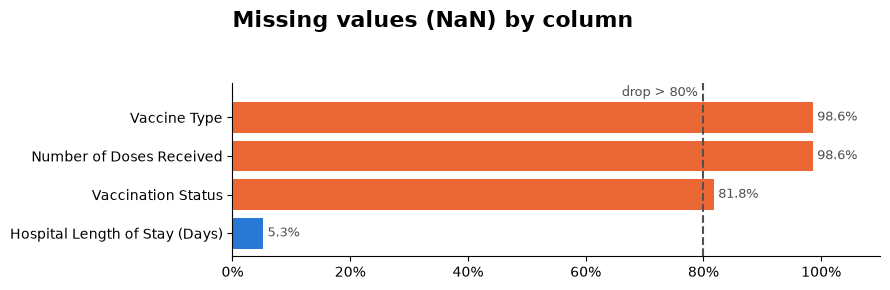

In [46]:
# 6 — Missingness per column (NaN), with the 80% drop threshold
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
plt.style.use('default')

na = data.isna().mean().mul(100).sort_values()
na = na[na > 0]

fig, ax = plt.subplots(figsize=(9, max(3, 0.32 * len(na) + 1)))
bars = ax.barh(na.index, na.values, color=['#eb6834' if v > 80 else '#2a78d6' for v in na.values])
ax.bar_label(bars, fmt='%.1f%%', padding=3, fontsize=9, color='#52514e')
ax.axvline(80, color='#52514e', ls='--', lw=1.5)
ax.text(79, len(na) - 0.45, 'drop > 80%', color='#52514e', fontsize=9, ha='right')
ax.set_title('Missing values (NaN) by column', loc='left', fontsize=16, fontweight='bold', pad=40)
ax.set_xlim(0, 110); ax.set_ylim(-0.6, len(na) - 0.1)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig('fig6_missingness.png', dpi=150, bbox_inches='tight'); plt.show()

In [47]:
# Complete Pre-Split Cleaning

data_clean = data.copy()
original_n = len(data_clean)  # 9332

# 0. Set suppressed Census Region to NaN (before split)
data_clean.loc[data_clean['Census Region'] == 'data suppressed', 'Census Region'] = np.nan

# 1. Drop columns with >80% NaN
data_clean = data_clean.drop(columns_drop, axis=1)

# 2. Drop Still admitted (LOS incomplete)
still = data_clean['Outcome'] == 'Still admitted'
data_clean = data_clean[~still]

# 3. Drop Unknown outcome with missing LOS
unk_nan = (data_clean['Outcome'] == 'Unknown') & (data_clean['Hospital Length of Stay (Days)'].isna())
data_clean = data_clean[~unk_nan]

# 4. Drop remaining missing LOS
nan_los = data_clean['Hospital Length of Stay (Days)'].isna()
data_clean = data_clean[~nan_los]

# 5. Drop negative LOS
neg_los = data_clean['Hospital Length of Stay (Days)'] < 0
data_clean = data_clean[~neg_los]

# 6. Drop severe same-day discharges (ICU or shock, LOS = 0) — likely transfers
error = ((data_clean['Outcome'] == 'Discharged') &
         (data_clean['Hospital Length of Stay (Days)'] == 0) &
         ((data_clean['ICU Level of Care'] == True) | (data_clean['Shock'] == True)))
data_clean = data_clean[~error]

# 7. Drop structurally useless columns (identifiers, near-constants)
useless_col = ['Case ID', 'SARS-CoV-2 Positive Test Type Not Specified', 'Vaccine Eligiblity',
               'Antigen Results', 'COVID-19 Exposure Only']
data_clean = data_clean.drop(useless_col, axis=1)

# 8. Combine race columns into one Race variable
race_cols = ['White Race', 'Black Race', 'Other Race', 'Unknown Race']
data_clean['Race'] = data_clean[race_cols].idxmax(axis=1).str.replace(' Race', '')
data_clean = data_clean.drop(columns=race_cols)

# 9. Drop Sex = 'Unknown' (n=3; too few to estimate, made CV fold fail)
sex_unk = data_clean['Sex'] == 'Unknown'
data_clean = data_clean[~sex_unk]

# 10. Variant period from MIS-C onset month
onset = pd.to_datetime(data_clean['MIS-C Onset (Month/Year)'], format='%m/%Y')
data_clean['Variant Period'] = np.select(
    [onset < '2021-07-01', onset < '2021-12-01'],
    ['Pre-Delta', 'Delta'], default='Omicron')

#### Data cleaning: 9,332 records → 8,795 in analysis (94.2% retained)

**Patients removed (in order):**

- Still admitted (LOS incomplete): **366** (3.9%)
- Unknown outcome, LOS missing: **99** (1.1%)
- LOS missing: **50** (0.5%)
- Negative LOS: **0**
- Severe same-day discharge (ICU or shock, LOS = 0; likely transfer): **19** (0.2%)
- Sex unknown: **3** (<0.1%)

**Columns removed:**

- More than 80% missing: Vaccination Status, Number of Doses Received, Vaccine Type
- Not useful for analysis: Case ID, SARS-CoV-2 Positive Test Type Not Specified, Vaccine Eligiblity, Antigen Results, COVID-19 Exposure Only
- White / Black / Other / Unknown Race, combined into one **Race** variable

**Changed or added:**

- Census region "data suppressed" (248 patients) set to missing
- **Variant Period** created from onset month: Pre-Delta, Delta, Omicron

In [48]:
# TABLE 1 — Patient characteristics by ICU admission (cleaned cohort)
from scipy import stats

def table1(df, group, cat_vars, bin_vars, cont_vars):
    g = df[group].map({True: 'ICU', False: 'No ICU', 1: 'ICU', 0: 'No ICU'})
    levels = ['No ICU', 'ICU']
    n = g.value_counts()
    rows = [{'Variable': 'N', 'Level': '',
             **{l: f"{n[l]:,}" for l in levels}, 'Overall': f"{len(df):,}", 'p': ''}]

    for v in cont_vars:                                    # median [IQR], Mann-Whitney
        x = pd.to_numeric(df[v], errors='coerce')
        f = lambda s: f"{s.median():.0f} [{s.quantile(.25):.0f}–{s.quantile(.75):.0f}]"
        p = stats.mannwhitneyu(*[x[g == l].dropna() for l in levels]).pvalue
        rows.append({'Variable': f"{v}, median [IQR]", 'Level': '',
                     **{l: f(x[g == l]) for l in levels}, 'Overall': f(x), 'p': p})

    for v in cat_vars:                                     # n (%), chi-square
        ct = pd.crosstab(df[v].fillna('Missing'), g)[levels]
        p = stats.chi2_contingency(ct)[1]
        for i, lvl in enumerate(ct.index):
            rows.append({'Variable': v if i == 0 else '', 'Level': lvl,
                         **{l: f"{ct.loc[lvl, l]:,} ({ct.loc[lvl, l]/ct[l].sum()*100:.1f})" for l in levels},
                         'Overall': f"{ct.loc[lvl].sum():,} ({ct.loc[lvl].sum()/ct.values.sum()*100:.1f})",
                         'p': p if i == 0 else ''})

    for v in bin_vars:                                     # n (%) yes, chi-square
        x = df[v].fillna(False).astype(bool)
        ct = pd.crosstab(x, g)[levels].reindex([False, True], fill_value=0)
        p = stats.chi2_contingency(ct)[1] if (ct > 0).all().all() else np.nan
        rows.append({'Variable': v, 'Level': 'Yes',
                     **{l: f"{ct.loc[True, l]:,} ({ct.loc[True, l]/ct[l].sum()*100:.1f})" for l in levels},
                     'Overall': f"{x.sum():,} ({x.mean()*100:.1f})", 'p': p})

    t = pd.DataFrame(rows)
    t['p'] = t['p'].apply(lambda p: '' if p == '' or pd.isna(p) else ('<0.001' if p < 0.001 else f"{p:.3f}"))
    return t

t1_df = data_clean.assign(**{'Census Region': data_clean['Census Region'].fillna('Suppressed')})
table_1 = table1(
    t1_df, group='ICU Level of Care',
    cont_vars=['Hospital Length of Stay (Days)'],
    cat_vars=['Age Group', 'Sex', 'Race', 'Ethnicity', 'Census Region', 'Variant Period', 'Outcome'],
    bin_vars=['Obesity', 'Chronic Lung Disease', 'All Other Comorbidities', 'Shock',
              'Intubation or Mechanical Ventilation', 'Severe Cardiac Involvement',
              'First IVIG', 'Second IVIG', 'Treated with Steroids'])

pd.set_option('display.max_rows', 200, 'display.width', 200)
#print(table_1.to_string(index=False))
table_1.to_excel('Table1_by_ICU.xlsx', index=False)

display(table_1.style
        .hide(axis='index')
        .set_properties(**{'text-align': 'left', 'padding': '6px 18px', 'font-size': '15px'})
        .set_table_styles([{'selector': 'th', 'props': 'text-align: left; padding: 6px 18px; font-size: 15px;'},
                           {'selector': 'caption', 'props': 'text-align: left; font-weight: bold; font-size: 17px; padding-bottom: 10px;'}])
        .set_caption('Table 1 — Patient characteristics by ICU admission (n (%) unless stated)'))

Variable,Level,No ICU,ICU,Overall,p
N,,"3,815","4,980","8,795",
"Hospital Length of Stay (Days), median [IQR]",,4 [3–5],6 [4–9],5 [4–7],<0.001
Age Group,1-4 years,"1,135 (29.8)",820 (16.5),"1,955 (22.2)",<0.001
,12-15 years,506 (13.3),"1,140 (22.9)","1,646 (18.7)",
,16-20 years,289 (7.6),552 (11.1),841 (9.6),
,5-11 years,"1,687 (44.2)","2,370 (47.6)","4,057 (46.1)",
,<1 year,198 (5.2),98 (2.0),296 (3.4),
Sex,Female,"1,539 (40.3)","1,960 (39.4)","3,499 (39.8)",0.362
,Male,"2,276 (59.7)","3,020 (60.6)","5,296 (60.2)",
Race,Black,874 (22.9),"1,679 (33.7)","2,553 (29.0)",<0.001


In [49]:
#  NOW SPLIT

from sklearn.model_selection import train_test_split

train_data, test_data = train_test_split(
    data_clean,
    test_size    = 0.20,
    random_state = 42,
    stratify     = data_clean['ICU Level of Care']
)

y_train = train_data[
    'Hospital Length of Stay (Days)'
].clip(lower=0).values

y_test  = test_data[
    'Hospital Length of Stay (Days)'
].clip(lower=0).values

print(f"\nAfter split:")
print(f"  Train: n={len(train_data):,}")
print(f"  Test:  n={len(test_data):,} ← LOCKED")


After split:
  Train: n=7,036
  Test:  n=1,759 ← LOCKED


In [50]:
train_data=train_data.reset_index(drop=True)
test_data=test_data.reset_index(drop=True)


In [51]:
from sklearn.impute import SimpleImputer

print(f"Before imputation:")
print(f"Train NaN: "
      f"{train_data['Census Region'].isna().sum()}")
print(f"Test  NaN: "
      f"{test_data['Census Region'].isna().sum()}")

region_imputer = SimpleImputer(strategy='most_frequent')

train_data = train_data.copy()
test_data  = test_data.copy()

train_data['Census Region'] = region_imputer.fit_transform(
    train_data[['Census Region']]   # fit on TRAIN
)[:, 0]

test_data['Census Region'] = region_imputer.transform(
    test_data[['Census Region']]    # apply to TEST
)[:, 0]

print(f"\nAfter imputation:")
print(f"Train NaN: "
      f"{train_data['Census Region'].isna().sum()}")
print(f"Test  NaN: "
      f"{test_data['Census Region'].isna().sum()}")

Before imputation:
Train NaN: 181
Test  NaN: 48

After imputation:
Train NaN: 0
Test  NaN: 0


In [52]:
# Step 2 — Reference categories (largest group, TRAIN only)

cat_cols = ['Age Group', 'Sex', 'Race', 'Ethnicity', 'Census Region', 'Variant Period']

references = {col: train_data[col].value_counts().idxmax() for col in cat_cols}

#### Reference categories (largest group in training data, n = 7,036)

- **Age Group:** 5-11 years — 3,254 (46.2%)
- **Sex:** Male — 4,256 (60.5%)
- **Race:** White — 3,133 (44.5%)
- **Ethnicity:** Not Hispanic or Latino — 4,550 (64.7%)
- **Census Region:** South — 3,064 (43.5%)
- **Variant Period:** Pre-Delta — 4,145 (58.9%)

Each model coefficient compares a group with its reference category.

In [53]:
# Step 3 — Categories and reference levels (from TRAIN only)

all_categories = {col: sorted(train_data[col].fillna('Missing').unique().tolist())
                  for col in cat_cols}
drop_refs = [references[col] for col in cat_cols]

#### Dummy variables (reference category dropped)

- **Age Group** (ref: 5-11 years): <1 year, 1-4 years, 12-15 years, 16-20 years
- **Sex** (ref: Male): Female
- **Race** (ref: White): Black, Other, Unknown
- **Ethnicity** (ref: Not Hispanic or Latino): Hispanic or Latino, Unknown
- **Census Region** (ref: South): Midwest, Northeast, West
- **Variant Period** (ref: Pre-Delta): Delta, Omicron

In [54]:
# Step 4 — Fit Encoder on Train, Apply to Test

# ── Build encoder with train-derived settings ─────────────
cat_encoder = OneHotEncoder(
    categories     = [all_categories[col]
                      for col in cat_cols],
    drop           = drop_refs,      # ← train references
    sparse_output  = False,
    handle_unknown = 'ignore'        # test unseen → zeros
)

In [55]:
#  Fit ONLY on train
X_train_cat = cat_encoder.fit_transform(
    train_data[cat_cols].fillna('Missing')
)

#  Apply to test (NO fitting)
X_test_cat  = cat_encoder.transform(
    test_data[cat_cols].fillna('Missing')
)

#  Get column names
cat_feature_names = cat_encoder.get_feature_names_out(
    cat_cols
)
X_train_cat_df = pd.DataFrame(
    X_train_cat,
    columns = cat_feature_names,
    index   = train_data.index
)

X_test_cat_df  = pd.DataFrame(
    X_test_cat,
    columns = cat_feature_names,
    index   = test_data.index
)

In [56]:
# Step 5 — Verify encoding (silent: stops with a message only if something is wrong)
assert list(X_train_cat_df.columns) == list(X_test_cat_df.columns), "Train/test dummy columns differ"
assert not X_train_cat_df.isna().any().any(), "NaN in train dummies"
assert not X_test_cat_df.isna().any().any(),  "NaN in test dummies"

for col, ref in zip(cat_cols, drop_refs):
    assert f"{col}_{ref}" not in X_train_cat_df.columns, f"{col}: reference column was not dropped"
    block  = X_train_cat_df[[c for c in X_train_cat_df.columns if c.startswith(f"{col}_")]]
    is_ref = train_data[col].fillna('Missing').astype(str).eq(ref).to_numpy()
    assert (block.sum(axis=1).to_numpy()[is_ref] == 0).all(),  f"{col}: reference rows not all 0"
    assert (block.sum(axis=1).to_numpy()[~is_ref] == 1).all(), f"{col}: non-reference rows not exactly one 1"

#### Variable selection decisions

- Case Definition Cardiac Involvement and Severe Cardiac Involvement are hierarchically related (severe is a subset), so **Severe** is kept and Case Definition is dropped.
- Treated with Vasopressors is excluded (overlaps with Shock).
- ICU Level of Care and Shock are kept (clinically important).

In [57]:
bin_cols = [
    'ICU Level of Care', 'Shock', 'ECMO', 'Dialysis',
    'Intubation or Mechanical Ventilation',
    'Severe Cardiac Involvement',
    'Severe Respiratory Involvement',
    'Severe Neurologic Involvement',
    'Severe Hematologic Involvement',
    'Severe Renal Involvement',
    'Severe Gastrointestinal Involvement',
    'Cardiac Dysfunction', 'Myocarditis',
    'Coronary Artery Aneurysm or Dilatation',
    'First IVIG', 'Second IVIG',
    'Treated with Steroids',
    'Treated with Immune modulators',
    'Treated with Anticoagulation',
    'Treated with Antiplatelets',
    'High Flow Nasal Cannula', 'Non-invasive Ventilation',
    'Obesity', 'All Other Comorbidities','Chronic Lung Disease'
]

X_train_bin = train_data[bin_cols].fillna(0).astype(float)
X_test_bin  = test_data[bin_cols].fillna(0).astype(float)

# ── Combine dummies + binary ──────────────────────────────
X_train = pd.concat([X_train_cat_df,
                     X_train_bin], axis=1)
X_test  = pd.concat([X_test_cat_df,
                     X_test_bin],  axis=1)


#### Final predictor matrix

- **40 predictors:** 15 dummy variables (age, sex, race, ethnicity, region, variant period) + 25 binary clinical variables
- **Train:** 7,036 patients · **Test:** 1,759 patients

In [58]:
# remove shock and All Other Comorbidities

# bin_cols1=[c for c in bin_cols if c != 'All Other Comorbidities']
bin_cols1=[c for c in bin_cols if c != 'Shock']

X_train_bin2 = train_data[bin_cols1].fillna(0).astype(float)
X_test_bin2  = test_data[bin_cols1].fillna(0).astype(float)

# ── Combine dummies + binary ──────────────────────────────
X_train2 = pd.concat([X_train_cat_df,
                     X_train_bin2], axis=1)
X_test2  = pd.concat([X_test_cat_df,
                     X_test_bin2],  axis=1)


X_train_const2 = sm.add_constant(X_train2)

nb_model2 = sm.NegativeBinomial(
    y_train,
    X_train_const2
).fit(method='bfgs', maxiter=300, disp=False)

**Sensitivity check: model without Shock**

- Full NB model: AIC **37,489.5**
- NB without Shock: AIC **37,488.1**
- Difference: **−1.3**, so the fit is practically the same.
- Shock overlaps with ICU care and intubation; the main results do not depend on it.

#### Variables kept regardless of p-value

- Demographic blocks (age, sex, race, ethnicity, region) are kept whole as standard confounders; dummies are never dropped one by one.
- Shock was considered for removal (p = 0.134, overlap with ICU and intubation) and tested with a sensitivity model.

In [59]:
# Step 2 — Metrics Function (Used for All Models)

def get_metrics(y_actual, y_pred, label):
    """
    Single function to evaluate any model
    Same metrics for fair comparison
    """
    # Clip predictions — LOS cannot be negative
    y_actual = np.asarray(y_actual, dtype=float)
    y_pred   = np.clip(np.asarray(y_pred, dtype=float), 0, None)

    mae     = mean_absolute_error(y_actual, y_pred)
    rmse    = np.sqrt(mean_squared_error(y_actual, y_pred))
    corr    = np.corrcoef(y_actual, y_pred)[0, 1]
    bias    = (y_pred - y_actual).mean()
    w5      = (np.abs(y_actual - y_pred) <= 5).mean() * 100
    w7      = (np.abs(y_actual - y_pred) <= 7).mean() * 100

    return {
        'Model': label,
        'MAE':   round(mae,  3),
        'RMSE':  round(rmse, 3),
        'Corr':  round(corr, 4),
        'Bias':  round(bias, 3),
        'W±5d':  round(w5,   1),
        'W±7d':  round(w7,   1)
    }

In [60]:
# Step 3 — Cross-Validation Function (Train Only)

def cross_validate(model, X, y,
                   is_statsmodels=False, family='nb',
                   k=5):
    """
    5-fold CV on TRAIN data only
    Works for both sklearn and statsmodels models
    Returns mean MAE and SD
    """
    kf   = KFold(n_splits=k,
                 shuffle=True,
                 random_state=42)
    maes = []

    for fold, (tr_idx, val_idx) in enumerate(
        kf.split(X), 1
    ):
        X_tr  = X.iloc[tr_idx]
        X_val = X.iloc[val_idx]
        y_tr  = y[tr_idx]
        y_val = y[val_idx]

        try:
            if is_statsmodels:
                if family == 'poisson':
                    m = sm.GLM(y_tr, sm.add_constant(X_tr),
                               family=sm.families.Poisson()).fit()
                else:
                    m = sm.NegativeBinomial(
                        y_tr,
                        sm.add_constant(X_tr)
                    ).fit(method='bfgs',
                          maxiter=300,
                          disp=False)
                pred = m.predict(
                    sm.add_constant(
                        X_val,
                        has_constant='add'
                    )
                )
            else:
                model.fit(X_tr, y_tr)
                pred = model.predict(X_val)

            pred = np.clip(pred, 0, None)
            maes.append(
                mean_absolute_error(y_val, pred)
            )

        except Exception as e:
            print(f"  Fold {fold} failed: "
                  f"{str(e)[:40]}")

    if maes:
        return round(np.mean(maes), 3), \
               round(np.std(maes),  3)
    return np.nan, np.nan

In [61]:
# Step 4 — Fit All Models
#
print("Fitting Negative Binomial...")

X_train_nb = sm.add_constant(X_train)
X_test_nb  = sm.add_constant(
    X_test, has_constant='add'
)

nb_model = sm.NegativeBinomial(
    y_train, X_train_nb
).fit(method='bfgs', maxiter=300, disp=False)

pred_nb_train = nb_model.predict(X_train_nb)
pred_nb_test  = nb_model.predict(X_test_nb)

cv_nb_mae, cv_nb_sd = cross_validate(
    None, X_train, y_train,
    is_statsmodels=True
)

print(f"  Converged: "
      f"{nb_model.mle_retvals.get('converged')}")
print(f"  AIC: {nb_model.aic:.2f}")
print(f"  CV MAE: {cv_nb_mae:.3f} ± {cv_nb_sd:.3f}")
print(f"  Test MAE: "
      f"{mean_absolute_error(y_test, pred_nb_test):.3f}")


Fitting Negative Binomial...
  Converged: True
  AIC: 37489.45
  CV MAE: 3.049 ± 0.329
  Test MAE: 3.090


In [62]:
# NB incidence rate ratios — IRR > 1 = longer stay
ci  = nb_model.conf_int()
irr = pd.DataFrame({'IRR': np.exp(nb_model.params), 'low': np.exp(ci[0]),
                    'high': np.exp(ci[1]), 'p': nb_model.pvalues}).drop(index=['const', 'alpha'])
irr.round(4).to_excel('NB_IRR.xlsx')

table = pd.DataFrame({
    'Variable':     irr.index.str.replace('_', ': ', n=1),
    'IRR (95% CI)': [f"{r.IRR:.2f} ({r.low:.2f}–{r.high:.2f})" for r in irr.itertuples()],
    'p-value':      ['<0.001' if p < 0.001 else f"{p:.3f}" for p in irr['p']],
})
sig = irr['p'].to_numpy() < 0.05
display(table.style
        .hide(axis='index')
        .apply(lambda _: ['font-weight: bold' if s else '' for s in sig],
               subset=['IRR (95% CI)', 'p-value'])
        .set_properties(**{'text-align': 'left', 'padding': '6px 18px', 'font-size': '15px'})
        .set_table_styles([{'selector': 'th', 'props': 'text-align: left; padding: 6px 18px; font-size: 15px;'},
                           {'selector': 'caption', 'props': 'text-align: left; font-weight: bold; font-size: 17px; padding-bottom: 10px;'}])
        .set_caption('Negative Binomial model — incidence rate ratios (bold = p < 0.05)'))

Variable,IRR (95% CI),p-value
Age Group: 1-4 years,1.09 (1.04–1.13),<0.001
Age Group: 12-15 years,0.95 (0.91–0.99),0.018
Age Group: 16-20 years,1.04 (0.99–1.10),0.128
Age Group: <1 year,1.68 (1.55–1.83),<0.001
Sex: Female,0.97 (0.94–1.00),0.076
Race: Black,1.02 (0.98–1.06),0.357
Race: Other,0.99 (0.95–1.04),0.750
Race: Unknown,0.97 (0.91–1.04),0.400
Ethnicity: Hispanic or Latino,1.03 (0.99–1.07),0.213
Ethnicity: Unknown,1.15 (1.08–1.22),<0.001


In [63]:
 # ── Add interactions (NB/Poisson only)

print("Fitting Negative Binomial with interaction terms...")

X_train_int = X_train.copy()
X_test_int = X_test.copy()

X_train_int['ICU_x_Shock'] = (
        X_train_int['ICU Level of Care'] * X_train_int['Shock']
)
X_test_int['ICU_x_Shock'] = (
        X_test_int['ICU Level of Care'] * X_test_int['Shock']
)

X_train_int['ICU_x_Cardiac'] = (X_train_int['ICU Level of Care'] *
                                X_train_int['Severe Cardiac Involvement'])

X_test_int['ICU_x_Cardiac'] = (
        X_test_int['ICU Level of Care'] *
        X_test_int['Severe Cardiac Involvement']
)

X_train_const_int = sm.add_constant(X_train_int)
X_test_const_int = sm.add_constant(X_test_int, has_constant='add')

nb_model_int = sm.NegativeBinomial(
    y_train,
    X_train_const_int
).fit(method='bfgs', maxiter=300, disp=False)

pred_nb_Int_train = nb_model_int.predict(X_train_const_int)
pred_nb_Int_test  = nb_model_int.predict(X_test_const_int)

cv_nb_Imae, cv_nb_Isd = cross_validate(
    None, X_train_int, y_train,
    is_statsmodels=True
)
# (cv_nb_mae,   cv_nb_sd)
print(f"  Converged: "
      f"{nb_model_int.mle_retvals.get('converged')}")
print(f"  AIC: {nb_model_int.aic:.2f}")
print(f"  CV MAE: {cv_nb_Imae:.3f} ± {cv_nb_Isd:.3f}")
print(f"  Test MAE: "
      f"{mean_absolute_error(y_test, pred_nb_Int_test):.3f}")


Fitting Negative Binomial with interaction terms...
  Converged: True
  AIC: 37466.95
  CV MAE: 3.055 ± 0.321
  Test MAE: 3.092


In [64]:
import statsmodels.api as sm

print("Fitting Poisson model...")

X_train_poi = sm.add_constant(X_train)
X_test_poi  = sm.add_constant(
    X_test, has_constant='add'
)

poisson_model = sm.GLM(
    y_train, X_train_poi,family=sm.families.Poisson()
).fit()

pred_pois_train = poisson_model.predict(X_train_poi)
pred_pois_test  = poisson_model.predict(X_test_poi)

cv_pois_mae, cv_pois_sd = cross_validate(
    None, X_train, y_train,
    is_statsmodels=True, family='poisson'
)

print(f"  Converged: "
      f"{poisson_model.converged}")
print(f"  AIC: {poisson_model.aic:.2f}")
print(f"  CV MAE: {cv_pois_mae:.3f} ± {cv_pois_sd:.3f}")
print(f"  Test MAE: "
      f"{mean_absolute_error(y_test, pred_pois_test):.3f}")


Fitting Poisson model...
  Converged: True
  AIC: 54048.18
  CV MAE: 3.067 ± 0.326
  Test MAE: 3.098


In [65]:
# Model 3 — Random Forest

rf_model = RandomForestRegressor(
    n_estimators     = 500,
    max_depth        = 10,
    min_samples_leaf = 20,
    random_state     = 42,
    n_jobs           = -1
)
rf_model.fit(X_train, y_train)

pred_rf_train = rf_model.predict(X_train)
pred_rf_test  = rf_model.predict(X_test)
cv_rf_mae, cv_rf_sd = cross_validate(
    RandomForestRegressor(
        n_estimators     = 200,
        max_depth        = 10,
        min_samples_leaf = 20,
        random_state     = 42,
        n_jobs           = -1
    ),
    X_train, y_train
)

print(f"  CV MAE: {cv_rf_mae:.3f} ± {cv_rf_sd:.3f}")
print(f"  Test MAE: "
      f"{mean_absolute_error(y_test, pred_rf_test):.3f}")
# 3. Calculate AIC manually
mse = mean_squared_error(y_train, pred_rf_train)
n = len(y_train)
k = X_train.shape[1] # Using number of features as k
aic_score = n * np.log(mse) + 2 * k
print(f"  AIC: {aic_score:.3f}")



  CV MAE: 3.103 ± 0.326
  Test MAE: 3.128
  AIC: 35740.154


In [66]:
# Model 4 — Gradient Boosting

print("\nFitting Gradient Boosting...")

gb_model = GradientBoostingRegressor(
    n_estimators     = 500,
    learning_rate    = 0.05,
    max_depth        = 4,
    min_samples_leaf = 20,
    subsample        = 0.8,
    random_state     = 42
)
gb_model.fit(X_train, y_train)
pred_gb_train = gb_model.predict(X_train)
pred_gb_test  = gb_model.predict(X_test)

cv_gb_mae, cv_gb_sd = cross_validate(
    GradientBoostingRegressor(
        n_estimators     = 200,
        learning_rate    = 0.05,
        max_depth        = 4,
        min_samples_leaf = 20,
        random_state     = 42
    ),
    X_train, y_train
)
print(f"  CV MAE: {cv_gb_mae:.3f} ± {cv_gb_sd:.3f}")
print(f"  Test MAE: "
      f"{mean_absolute_error(y_test, pred_gb_test):.3f}")


Fitting Gradient Boosting...
  CV MAE: 3.211 ± 0.342
  Test MAE: 3.416


In [67]:
# ADMISSION-ONLY PREDICTION MODEL
# Uses only what is known when the child arrives: demographics, region,
# variant period and comorbidities. No ICU, ventilation, organ involvement
# or treatments (those happen DURING the stay = leakage).
admission_bin = ['Obesity', 'Chronic Lung Disease', 'All Other Comorbidities']

X_train_adm = pd.concat([X_train_cat_df, train_data[admission_bin].fillna(0).astype(float)], axis=1)
X_test_adm  = pd.concat([X_test_cat_df,  test_data[admission_bin].fillna(0).astype(float)],  axis=1)

nb_adm = sm.NegativeBinomial(y_train, sm.add_constant(X_train_adm)).fit(
    method='bfgs', maxiter=300, disp=False)
pred_adm_train = nb_adm.predict(sm.add_constant(X_train_adm))
pred_adm_test  = nb_adm.predict(sm.add_constant(X_test_adm, has_constant='add'))
cv_adm_mae, cv_adm_sd = cross_validate(None, X_train_adm, y_train, is_statsmodels=True)

# Compare: naive baseline vs admission-only vs full model
yt   = np.asarray(y_test, float)
base = np.full_like(yt, np.median(y_train))
rows = {'Baseline (train median)': base,
        'NB admission-only':       np.asarray(pred_adm_test, float),
        'NB full (in-hospital)':   np.asarray(pred_nb_test, float)}
print(f"Admission-only NB converged: {nb_adm.mle_retvals.get('converged')} | "
      f"predictors: {X_train_adm.shape[1]} | CV MAE: {cv_adm_mae:.3f} ± {cv_adm_sd:.3f}\n")
print(f"{'Model':<26}{'Test MAE':>9}{'MedAE':>7}{'Spearman':>10}")
for name, p in rows.items():
    sp = stats.spearmanr(yt, p)[0] if name != 'Baseline (train median)' else np.nan
    print(f"{name:<26}{np.abs(yt-p).mean():>9.3f}{np.median(np.abs(yt-p)):>7.2f}{sp:>10.3f}")


Admission-only NB converged: True | predictors: 18 | CV MAE: 3.766 ± 0.257

Model                      Test MAE  MedAE  Spearman
Baseline (train median)       3.413   2.00       nan
NB admission-only             3.751   2.42     0.219
NB full (in-hospital)         3.090   1.74     0.552


In [68]:
# ── Collect all results ───────────────────────────────────
all_preds = {
    'Negative Binomial':  pred_nb_test,
    'Negative Bin + Int': pred_nb_Int_test,
    'Poisson':            pred_pois_test,
    'Random Forest':      pred_rf_test,
    'Grad Boosting':      pred_gb_test,
}
cv_maes = {
    'Negative Binomial':  (cv_nb_mae,   cv_nb_sd),
    'Negative Bin + Int': (cv_nb_Imae,  cv_nb_Isd),
    'Poisson':            (cv_pois_mae, cv_pois_sd),
    'Random Forest':      (cv_rf_mae,   cv_rf_sd),
    'Grad Boosting':      (cv_gb_mae,   cv_gb_sd),
}

results = []
for name, pred in all_preds.items():
    m = get_metrics(y_test, pred, name)
    m['CV_MAE'], m['CV_SD'] = cv_maes[name]
    results.append(m)
results_df = pd.DataFrame(results).sort_values('MAE')

# ── Display as a formatted table ──────────────────────────
table = pd.DataFrame({
    'Model':          results_df['Model'],
    'CV MAE (± SD)':  [f"{a:.3f} ± {b:.3f}" for a, b in zip(results_df['CV_MAE'], results_df['CV_SD'])],
    'Test MAE':       results_df['MAE'].map('{:.3f}'.format),
    'RMSE':           results_df['RMSE'].map('{:.2f}'.format),
    'Correlation':    results_df['Corr'].map('{:.3f}'.format),
    'Within ±5 days': results_df['W±5d'].map('{:.1f}%'.format),
    'Bias (days)':    results_df['Bias'].map('{:+.3f}'.format),
})
best = (results_df['MAE'] == results_df['MAE'].min()).to_numpy()

display(table.style
        .hide(axis='index')
        .apply(lambda _: ['font-weight: bold' if b else '' for b in best], axis=0)
        .set_properties(**{'text-align': 'left', 'padding': '6px 18px', 'font-size': '15px'})
        .set_table_styles([{'selector': 'th', 'props': 'text-align: left; padding: 6px 18px; font-size: 15px;'},
                           {'selector': 'caption', 'props': 'text-align: left; font-weight: bold; font-size: 17px; padding-bottom: 10px;'}])
        .set_caption('Model comparison (bold = lowest test MAE)'))

Model,CV MAE (± SD),Test MAE,RMSE,Correlation,Within ±5 days,Bias (days)
Negative Binomial,3.049 ± 0.329,3.090,12.53,0.244,90.3%,-0.071
Negative Bin + Int,3.055 ± 0.321,3.092,12.53,0.244,90.2%,-0.070
Poisson,3.067 ± 0.326,3.098,12.53,0.245,90.2%,-0.063
Random Forest,3.103 ± 0.326,3.128,12.54,0.246,89.1%,+0.018
Grad Boosting,3.211 ± 0.342,3.397,12.83,0.215,87.7%,+0.081


- **CV MAE:** 5-fold cross-validation on the training set (used to choose the model)
- **Test MAE:** held-out test set (final reported result)

In [69]:
# ── Overfitting check: train vs test MAE ──────────────────
train_preds = {
    'Negative Binomial':  pred_nb_train,
    'Negative Bin + Int': pred_nb_Int_train,
    'Poisson':            pred_pois_train,
    'Random Forest':      pred_rf_train,
    'Grad Boosting':      pred_gb_train,
}

rows = []
for name in all_preds:
    mae_tr = mean_absolute_error(y_train, np.clip(train_preds[name], 0, None))
    mae_te = mean_absolute_error(y_test,  np.clip(all_preds[name],  0, None))
    gap    = mae_te - mae_tr
    rows.append({'Model': name,
                 'Train MAE': f"{mae_tr:.3f}",
                 'Test MAE':  f"{mae_te:.3f}",
                 'Gap':       f"{gap:+.3f}",
                 'Generalisation': ('Good' if gap < 0.5 else
                                    'Slight overfitting' if gap < 1.5 else 'Overfitting')})
overfit = pd.DataFrame(rows)

display(overfit.style
        .hide(axis='index')
        .set_properties(**{'text-align': 'left', 'padding': '6px 18px', 'font-size': '15px'})
        .set_table_styles([{'selector': 'th', 'props': 'text-align: left; padding: 6px 18px; font-size: 15px;'},
                           {'selector': 'caption', 'props': 'text-align: left; font-weight: bold; font-size: 17px; padding-bottom: 10px;'}])
        .set_caption('Overfitting check: train vs test MAE'))

Model,Train MAE,Test MAE,Gap,Generalisation
Negative Binomial,3.007,3.090,+0.084,Good
Negative Bin + Int,3.013,3.092,+0.079,Good
Poisson,3.009,3.098,+0.089,Good
Random Forest,2.951,3.128,+0.177,Good
Grad Boosting,2.928,3.397,+0.469,Good


- **Gap** = test MAE − train MAE. Under 0.5 days = good generalisation; 0.5–1.5 = slight overfitting; over 1.5 = overfitting.
- All models generalise well. The regression models (NB, Poisson) have the smallest gaps (≈0.08); Gradient Boosting has the largest (0.47), close to the threshold.

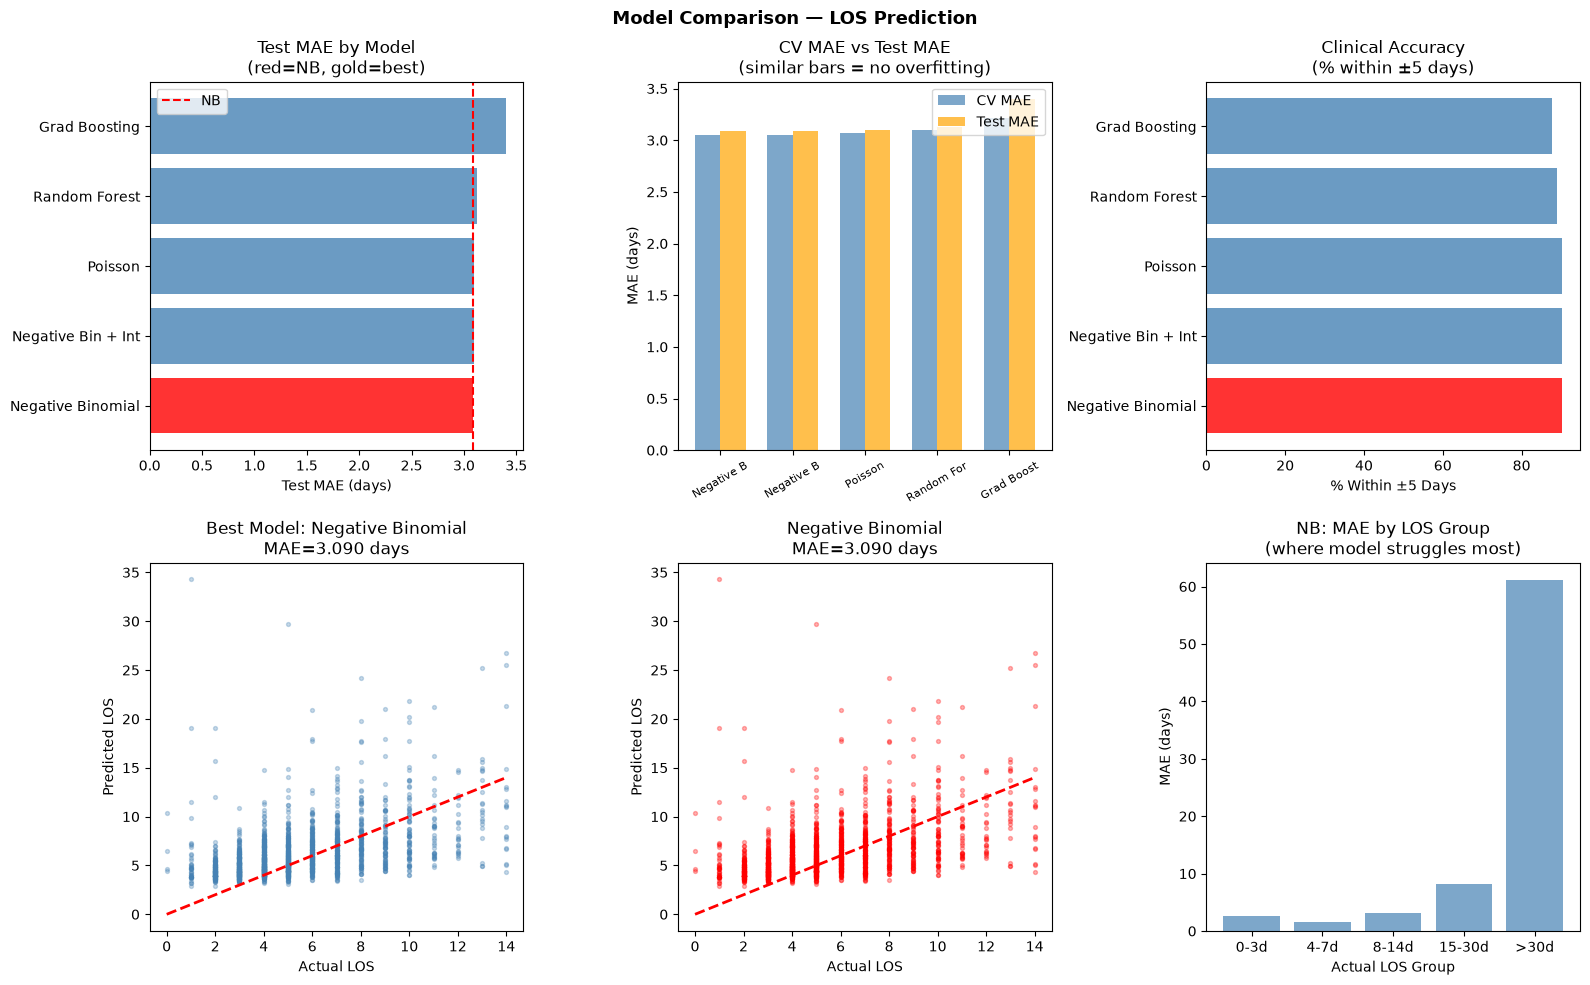

In [70]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

models_ordered = results_df['Model'].tolist()
test_maes      = results_df['MAE'].tolist()
cv_maes_plot   = results_df['CV_MAE'].tolist()
colors         = [
    'red' if m == 'Negative Binomial'
    else 'gold' if mae == min(test_maes)
    else 'steelblue'
    for m, mae in zip(models_ordered, test_maes)
]

# ── Plot 1: Test MAE comparison ───────────────────────────
axes[0,0].barh(
    models_ordered, test_maes,
    color=colors, alpha=0.8
)
axes[0,0].set_xlabel('Test MAE (days)')
axes[0,0].set_title(
    'Test MAE by Model\n'
    '(red=NB, gold=best)'
)
axes[0,0].axvline(
    results_df[results_df['Model']==
               'Negative Binomial']['MAE'].values[0],
    color='red', linestyle='--',
    linewidth=1.5, label='NB'
)
axes[0,0].legend()

# ── Plot 2: CV MAE vs Test MAE ────────────────────────────
x   = np.arange(len(models_ordered))
w   = 0.35
axes[0,1].bar(
    x - w/2, cv_maes_plot,
    w, label='CV MAE', color='steelblue', alpha=0.7
)
axes[0,1].bar(
    x + w/2, test_maes,
    w, label='Test MAE', color='orange', alpha=0.7
)
axes[0,1].set_xticks(x)
axes[0,1].set_xticklabels(
    [m[:10] for m in models_ordered],
    rotation=30, fontsize=8
)
axes[0,1].set_ylabel('MAE (days)')
axes[0,1].set_title(
    'CV MAE vs Test MAE\n'
    '(similar bars = no overfitting)'
)
axes[0,1].legend()

# ── Plot 3: Within ±5 days ────────────────────────────────
w5_vals = results_df['W±5d'].tolist()
axes[0,2].barh(
    models_ordered, w5_vals,
    color=colors, alpha=0.8
)
axes[0,2].set_xlabel('% Within ±5 Days')
axes[0,2].set_title('Clinical Accuracy\n(% within ±5 days)')

# ── Plot 4: Actual vs Predicted — best model ─────────────
best_model_name = results_df.iloc[0]['Model']
best_pred       = all_preds[best_model_name]
cap             = np.percentile(y_test, 95)
mask            = y_test <= cap

axes[1,0].scatter(
    y_test[mask], best_pred[mask],
    alpha=0.3, s=8, color='steelblue'
)
axes[1,0].plot(
    [0,cap],[0,cap], 'r--', linewidth=2
)
axes[1,0].set_xlabel('Actual LOS')
axes[1,0].set_ylabel('Predicted LOS')
axes[1,0].set_title(
    f'Best Model: {best_model_name}\n'
    f'MAE={results_df.iloc[0]["MAE"]:.3f} days'
)

# ── Plot 5: Actual vs Predicted — NB ─────────────────────
nb_pred = all_preds['Negative Binomial']
axes[1,1].scatter(
    y_test[mask], nb_pred[mask],
    alpha=0.3, s=8, color='red'
)
axes[1,1].plot(
    [0,cap],[0,cap], 'r--', linewidth=2
)
axes[1,1].set_xlabel('Actual LOS')
axes[1,1].set_ylabel('Predicted LOS')
nb_mae = results_df[
    results_df['Model']=='Negative Binomial'
]['MAE'].values[0]
axes[1,1].set_title(
    f'Negative Binomial\n'
    f'MAE={nb_mae:.3f} days'
)

# ── Plot 6: MAE by LOS group — NB ────────────────────────
bins   = [0, 3, 7, 14, 30, np.inf]
labels = ['0-3d','4-7d','8-14d','15-30d','>30d']
grps   = pd.cut(y_test, bins=bins, labels=labels)
resid  = y_test - np.clip(nb_pred, 0, None)

mae_by = pd.DataFrame({
    'group': grps,
    'err':   np.abs(resid)
}).groupby('group', observed=True)['err'].mean()

axes[1,2].bar(
    mae_by.index, mae_by.values,
    color='steelblue', alpha=0.7
)
axes[1,2].set_xlabel('Actual LOS Group')
axes[1,2].set_ylabel('MAE (days)')
axes[1,2].set_title(
    'NB: MAE by LOS Group\n'
    '(where model struggles most)'
)

plt.suptitle(
    'Model Comparison — LOS Prediction',
    fontsize=13, fontweight='bold'
)
plt.tight_layout()
plt.show()

**Final model selection**

- **Negative Binomial** has the lowest error on both cross-validation (CV MAE **3.049**) and the test set (test MAE **3.090**), so it is the primary model.
- It is also the most interpretable: incidence rate ratios (IRRs) give each factor's effect on length of stay directly.
- Poisson, NB with interactions and Random Forest perform almost the same (test MAE 3.09–3.13); Gradient Boosting is worst (3.40).

**Primary model (NB) on the test set:**

- Test MAE: **3.09 days**
- Test RMSE: **12.53 days** (inflated by a few very long stays)
- Within ±5 days: **90.3%** of patients
- Bias: **−0.07 days** (practically unbiased)

**Limitation:** predicting the median (5 days) for every patient gives a test MAE of about 3.41, so the model improves on this only modestly (about 9%). The model is best used to explain which factors are linked to longer stays, not to predict an individual child's stay.